# U.S. disaster declaration trends
**Ty Hafke | CIS 320, Grand Valley State University | Portfolio revision, November 2026**

This project examines how federal disaster declaration frequency and incident composition changed over time. It preserves the original streamgraph approach, with a corrected unit of analysis and a small companion time series for numerical context.

**Research questions:** Have annual FEMA declaration counts changed? Which incident categories are most common, and which contribute most to the difference between two historical periods?

Source: [OpenFEMA Disaster Declarations Summaries v2](https://www.fema.gov/openfema-data-page/disaster-declarations-summaries-v2), June 2026 snapshot. A declaration is an administrative action, not necessarily a distinct physical disaster. The analysis includes all declaration and incident types, including biological events.

## 1. Load and validate the source data
The source CSV is included in `data/`. The latest represented fiscal year (2026) was incomplete at the time of the snapshot, so the analysis uses FY 1953–2025. FEMA's reported `fyDeclared` is retained rather than recalculating a calendar year.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image

DATA = Path("data/DisasterDeclarationsSummaries.csv")
FIRST_YEAR, LAST_YEAR = 1953, 2025
raw = pd.read_csv(DATA, low_memory=False)
print(f"Source: {len(raw):,} rows, {raw.shape[1]} columns")
print("Latest declaration date:", raw["declarationDate"].max()[:10])

# Check the fields needed for the analysis.
fields = ["disasterNumber", "femaDeclarationString", "fyDeclared",
          "incidentType", "state", "declarationType"]
assert raw[fields].notna().all().all(), "Missing values in analysis fields"
assert not raw.duplicated().any(), "Exact duplicate rows found"
# Repeated declaration numbers must agree on the analysis fields.
assert raw.groupby("disasterNumber")[fields[1:]].nunique().le(1).all().all()
assert raw["disasterNumber"].nunique() == raw["femaDeclarationString"].nunique()
display(raw[fields].head())

Source: 69,936 rows, 28 columns
Latest declaration date: 2026-06-16


,disasterNumber,femaDeclarationString,fyDeclared,incidentType,state,declarationType
0,3610,EM-3610-PR,2024,Severe Storm,PR,EM
1,5529,FM-5529-OR,2024,Fire,OR,FM
2,5528,FM-5528-OR,2024,Fire,OR,FM
3,5527,FM-5527-OR,2024,Fire,OR,FM
4,3610,EM-3610-PR,2024,Severe Storm,PR,EM


## 2. Create a declaration-level dataset
The raw file has multiple designated-area records per declaration. Retain one record per `disasterNumber` after checking that the repeated records agree. This avoids weighting declarations by their number of area records. A single physical event can still generate several declaration numbers across jurisdictions or declaration types.

In [2]:
declarations = raw.drop_duplicates(subset="disasterNumber").copy()
analysis = declarations[declarations["fyDeclared"].between(FIRST_YEAR, LAST_YEAR)].copy()
print(f"Unique declarations in snapshot: {len(declarations):,}")
print(f"Declarations in complete fiscal years: {len(analysis):,}")
print(f"Excluded from analysis: {len(declarations) - len(analysis):,}")
print("Declaration types:")
display(analysis["declarationType"].value_counts().to_frame("Declarations"))

Unique declarations in snapshot: 5,192
Declarations in complete fiscal years: 5,126
Excluded from analysis: 66
Declaration types:


,Declarations
declarationType,
DR,2885
FM,1613
EM,628


## 3. Aggregate by year and incident type
Keep the seven most frequent incident types, as in the original project, and combine remaining types into Other. Reindex to include every year; check that the aggregated counts reconcile to the declaration-level data.

In [3]:
type_totals = analysis["incidentType"].value_counts()
top_types = type_totals.head(7).index.tolist()
analysis["type_grouped"] = analysis["incidentType"].where(
    analysis["incidentType"].isin(top_types), "Other")

counts = (analysis.groupby(["fyDeclared", "type_grouped"]).size()
          .unstack(fill_value=0)
          .reindex(index=range(FIRST_YEAR, LAST_YEAR + 1), fill_value=0)
          .reindex(columns=top_types + ["Other"], fill_value=0))
annual = counts.sum(axis=1)
assert annual.sum() == len(analysis)
assert counts.sum().sum() == len(analysis)

display(type_totals.head(7).to_frame("Declarations"))
display(annual.nlargest(5).to_frame("Declarations"))

,Declarations
incidentType,
Fire,1718
Severe Storm,1124
Flood,912
Hurricane,453
Tornado,182
Snowstorm,171
Biological,167


,Declarations
fyDeclared,
2020,315
2011,236
2024,162
2006,151
1996,149


## 4. Visualize historical trends
A streamgraph shows the changing composition and total volume; the width of each band represents annual counts. The floating baseline makes exact values difficult to read, so a small line chart below it supplies a common numerical scale and five-year trailing average. No smoothing is applied to the streamgraph.

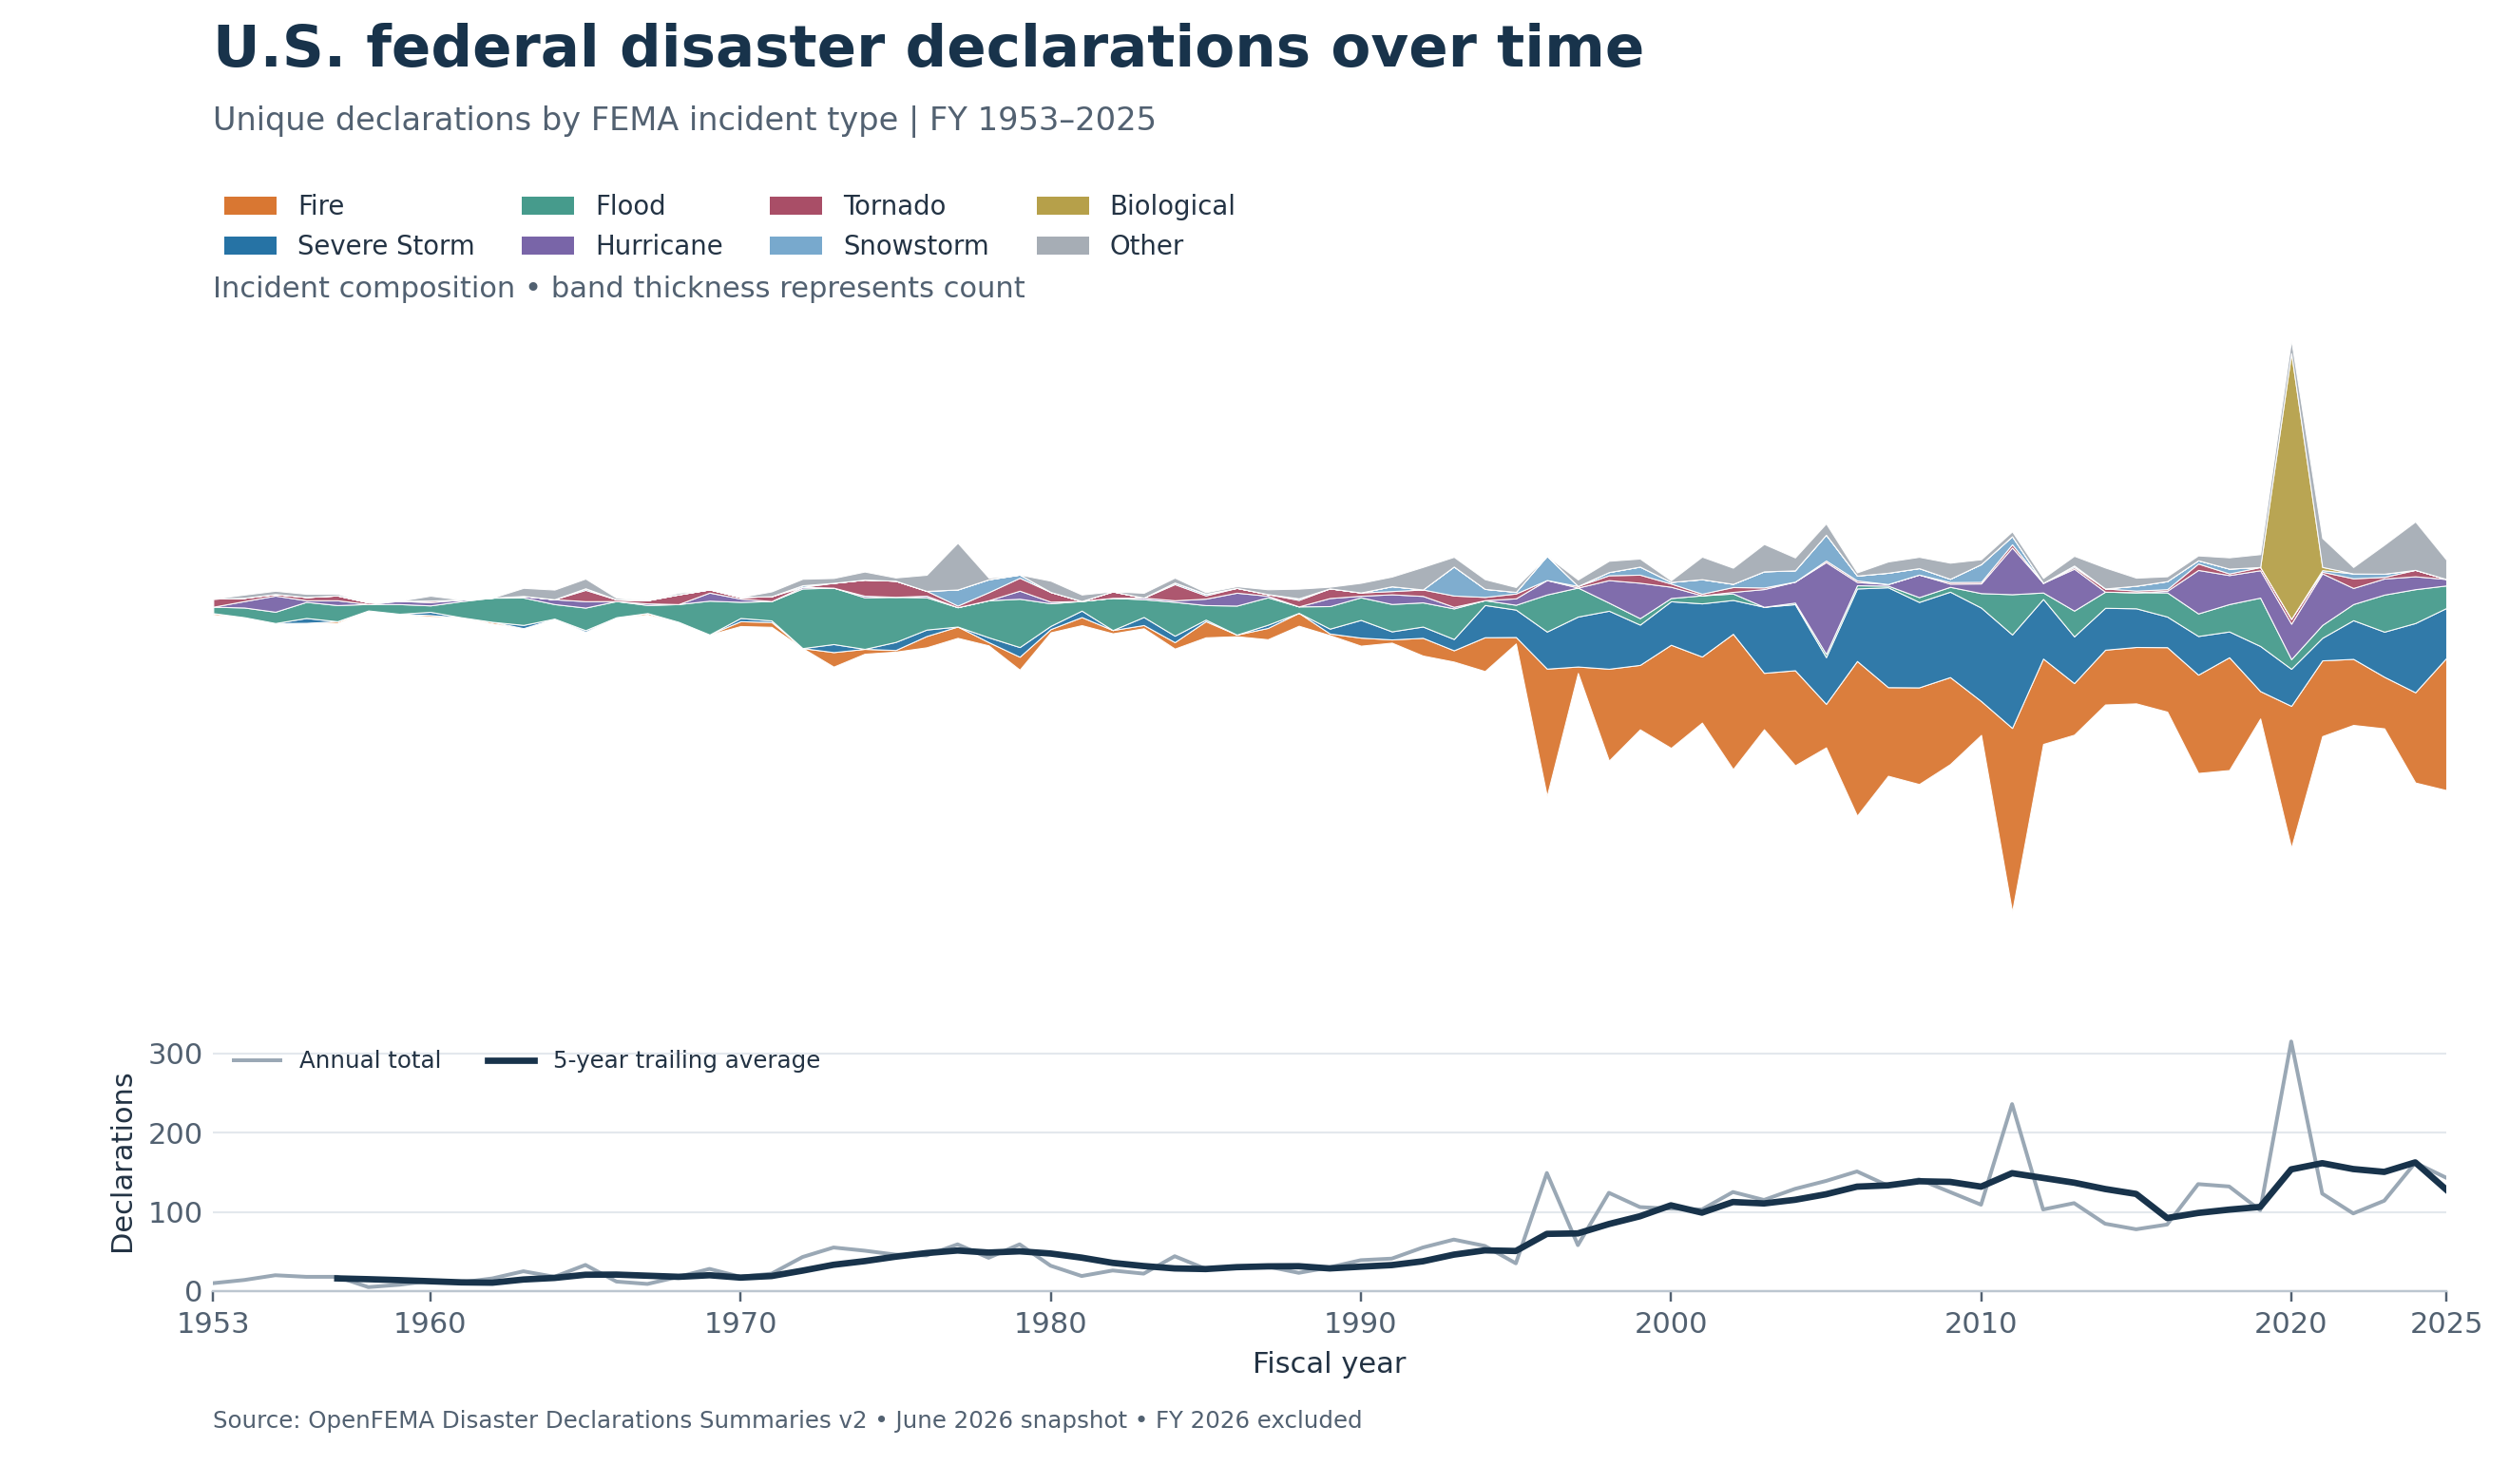

In [4]:
# A consistent palette and a compact legend keep the categories readable.
colors = ["#D97732", "#2673A5", "#469B8C", "#7965A8",
          "#A94E67", "#78A9CD", "#B6A04A", "#A6ADB5"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "text.color": "#233344", "axes.labelcolor": "#233344",
                     "xtick.color": "#526171", "ytick.color": "#526171"})
fig, (ax, line_ax) = plt.subplots(2, 1, figsize=(12, 7.1), sharex=True,
                                 gridspec_kw={"height_ratios": [2.4, 1]})
fig.subplots_adjust(left=.085, right=.975, top=.79, bottom=.13, hspace=.20)
fig.text(.085, .955, "U.S. federal disaster declarations over time",
         fontsize=20, weight="bold", color="#18334B")
fig.text(.085, .912, "Unique declarations by FEMA incident type | FY 1953–2025",
         fontsize=11, color="#526171")
handles = [Patch(facecolor=c, label=t) for t, c in zip(counts.columns, colors)]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(.08, .885),
           ncol=4, frameon=False, fontsize=9, columnspacing=1.8)
ax.stackplot(counts.index, counts.T.to_numpy(), baseline="wiggle",
             colors=colors, alpha=.95, linewidth=.35, edgecolor="white")
ax.set_yticks([])
ax.tick_params(axis="x", bottom=False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Incident composition • band thickness represents count", loc="left",
             fontsize=10, color="#526171", pad=5)

line_ax.plot(annual.index, annual, color="#9AA8B5", linewidth=1.3, label="Annual total")
line_ax.plot(annual.index, annual.rolling(5).mean(), color="#18334B",
             linewidth=2.2, label="5-year trailing average")
line_ax.set_ylabel("Declarations")
line_ax.set_ylim(bottom=0)
line_ax.set_xlim(FIRST_YEAR, LAST_YEAR)
line_ax.set_xticks([1953, 1960, 1970, 1980, 1990, 2000, 2010, 2020, 2025])
line_ax.set_xlabel("Fiscal year")
line_ax.grid(axis="y", color="#E3E8ED", linewidth=.7)
line_ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    line_ax.spines[side].set_visible(False)
line_ax.spines["bottom"].set_color("#BCC6D0")
line_ax.tick_params(axis="y", length=0)
line_ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=8)
fig.text(.085, .038, "Source: OpenFEMA Disaster Declarations Summaries v2 • June 2026 snapshot • FY 2026 excluded",
         fontsize=8, color="#526171")
fig.savefig("streamgraph.png", dpi=220, facecolor="white")
plt.close(fig)
display(Image(filename="streamgraph.png", width=1000))

## 5. Quantify the historical difference
Compare two equal-length, non-overlapping ten-year windows: FY 1980–1989 and FY 2015–2024. This is a descriptive comparison, not a fitted growth model. The difference in counts avoids undefined percentage growth for categories with zero initial declarations.

In [5]:
early = analysis[analysis["fyDeclared"].between(1980, 1989)]["incidentType"].value_counts()
recent = analysis[analysis["fyDeclared"].between(2015, 2024)]["incidentType"].value_counts()
comparison = pd.concat([early.rename("1980–1989"), recent.rename("2015–2024")], axis=1)
comparison = comparison.fillna(0).astype(int)
comparison["Change"] = comparison["2015–2024"] - comparison["1980–1989"]
comparison = comparison.sort_values("Change", ascending=False)
display(comparison.head(7))
print(f"Annual averages: {early.sum()/10:.1f} vs. {recent.sum()/10:.1f}")
print(f"Ratio of annual averages: {recent.sum()/early.sum():.2f}")
print("FY 2020 biological declarations:",
      len(analysis[(analysis["fyDeclared"] == 2020) & (analysis["incidentType"] == "Biological")]))
print("FY 2005 hurricane declarations:",
      len(analysis[(analysis["fyDeclared"] == 2005) & (analysis["incidentType"] == "Hurricane")]))

,1980–1989,2015–2024,Change
incidentType,,,
Fire,42,487,445
Severe Storm,21,243,222
Biological,0,167,167
Hurricane,21,145,124
Tropical Storm,0,28,28
Flood,134,154,20
Snowstorm,3,19,16


Annual averages: 28.6 vs. 134.3
Ratio of annual averages: 4.70
FY 2020 biological declarations: 165
FY 2005 hurricane declarations: 57


## 6. Findings and limitations
- The 5,126 unique declarations in FY 1953–2025 include 1,718 fire, 1,124 severe storm and 912 flood declarations. Fire is the largest category by declaration count, unlike the original area-record analysis.
- The two comparison windows averaged 28.6 and 134.3 declarations per year, respectively (4.70 times as many). Fire had the largest absolute increase (+445), followed by severe storms (+222).
- FY 2020 had 315 declarations, including 165 biological declarations. FY 2005 had 57 hurricane declarations. These spikes should not be interpreted as counts of distinct hurricanes or disease outbreaks.
- Federal declaration policy, eligibility, reporting and changes in declaration practice can influence the series. The dataset includes emergency, major disaster and fire management declarations; these categories represent different administrative actions. Counts are not direct measures of hazard frequency, damage or personal risk.
- The national aggregation does not establish whether any particular state or household is becoming more vulnerable. A streamgraph favors composition over precise values, which is why the companion line chart and comparison table are included.

**Conclusion:** The later comparison period has substantially more recorded FEMA declarations. Fire and severe storm declarations account for the largest absolute category increases between the selected windows. This is evidence about administrative declaration activity, not proof of a change in the underlying frequency of natural disasters.